# Final Exam: Digital Insomnia - Screen Habits and Sleep Analysis

**Student Name:** Rim Zaher  
**Course:** AIT620 - Methods of Artificial Intelligence and Machine Learning
**Institution:** University of The Potomac  
**Instructor:** Dr. Akal  
**Date:** October 25, 2026  

---

### Project Overview
This notebook analyzes how evening screen habits, caffeine consumption, and app usage impact sleep debt and fatigue levels. We perform exploratory data analysis (EDA) with visualization charts and summary tables, followed by pre-processing and model training using scikit-learn.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix

# Load dataset directly from raw GitHub URL to keep notebook fully self-contained
url = 'https://raw.githubusercontent.com/rimzaher-code/AIT680-Final-Exam-RimZaher/refs/heads/main/sleep_debt_screen_time.csv'
df = pd.read_csv(url)

# Display initial data check
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 rows:")
display(df.head())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nMissing Values Count:")
print(df.isnull().sum())

Dataset Dimensions: 8500 rows, 23 columns

First 5 rows:


,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild



Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8500 non-null   int64  
 1   age                         8500 non-null   int64  
 2   gender                      8500 non-null   object 
 3   chronotype                  8500 non-null   object 
 4   occupation                  8500 non-null   object 
 5   bedtime_hour                8500 non-null   float64
 6   screen_time_before_bed_min  8500 non-null   int64  
 7   primary_app_category        8500 non-null   object 
 8   screen_brightness_pct       8500 non-null   int64  
 9   blue_light_filter_on        8500 non-null   bool   
 10  caffeine_intake_mg          8500 non-null   int64  
 11  caffeine_last_hour          8500 non-null   float64
 12  physical_activity_min       8500 non-null   int64  
 13  

## 1. Exploratory Data Analysis (EDA)

In this section, we examine the dataset using statistical tables and visualizations to uncover patterns between screen time, caffeine habits, and sleep metrics.

=== Summary Statistics for Numerical Features ===


,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score
count,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00
mean,4250.50,28.10,13.88,53.74,68.77,79.65,15.91,29.76,70.08,34.97,31.40,6.78,16.93,17.54,2.33,81.99,4.55
std,2453.88,9.01,10.84,35.35,18.92,78.35,3.84,30.00,3.96,10.01,8.71,0.87,2.43,2.38,1.62,4.58,0.95
min,1.00,16.00,0.00,5.00,5.00,0.00,6.00,0.00,58.00,10.00,6.00,3.91,7.60,9.10,0.00,59.60,1.07
25%,2125.75,21.00,1.09,29.00,56.00,22.00,13.20,8.00,67.40,28.20,25.50,6.18,15.30,15.90,1.00,79.10,3.89
50%,4250.50,27.00,22.20,45.00,69.00,55.50,16.00,20.00,70.10,35.00,30.80,6.77,16.90,17.50,2.00,82.20,4.52
75%,6375.25,34.00,23.15,68.00,83.00,113.00,18.70,42.00,72.70,41.50,36.70,7.37,18.60,19.10,3.00,85.10,5.18
max,8500.00,65.00,24.00,240.00,100.00,500.00,23.00,180.00,82.00,70.00,75.20,9.69,27.30,28.70,11.00,95.40,8.85


/tmp/ipykernel_1636/661433104.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, ax=axes[0, 0], palette="crest")
/tmp/ipykernel_1636/661433104.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=num_cols[0], ax=axes[1, 0], palette="Set2")


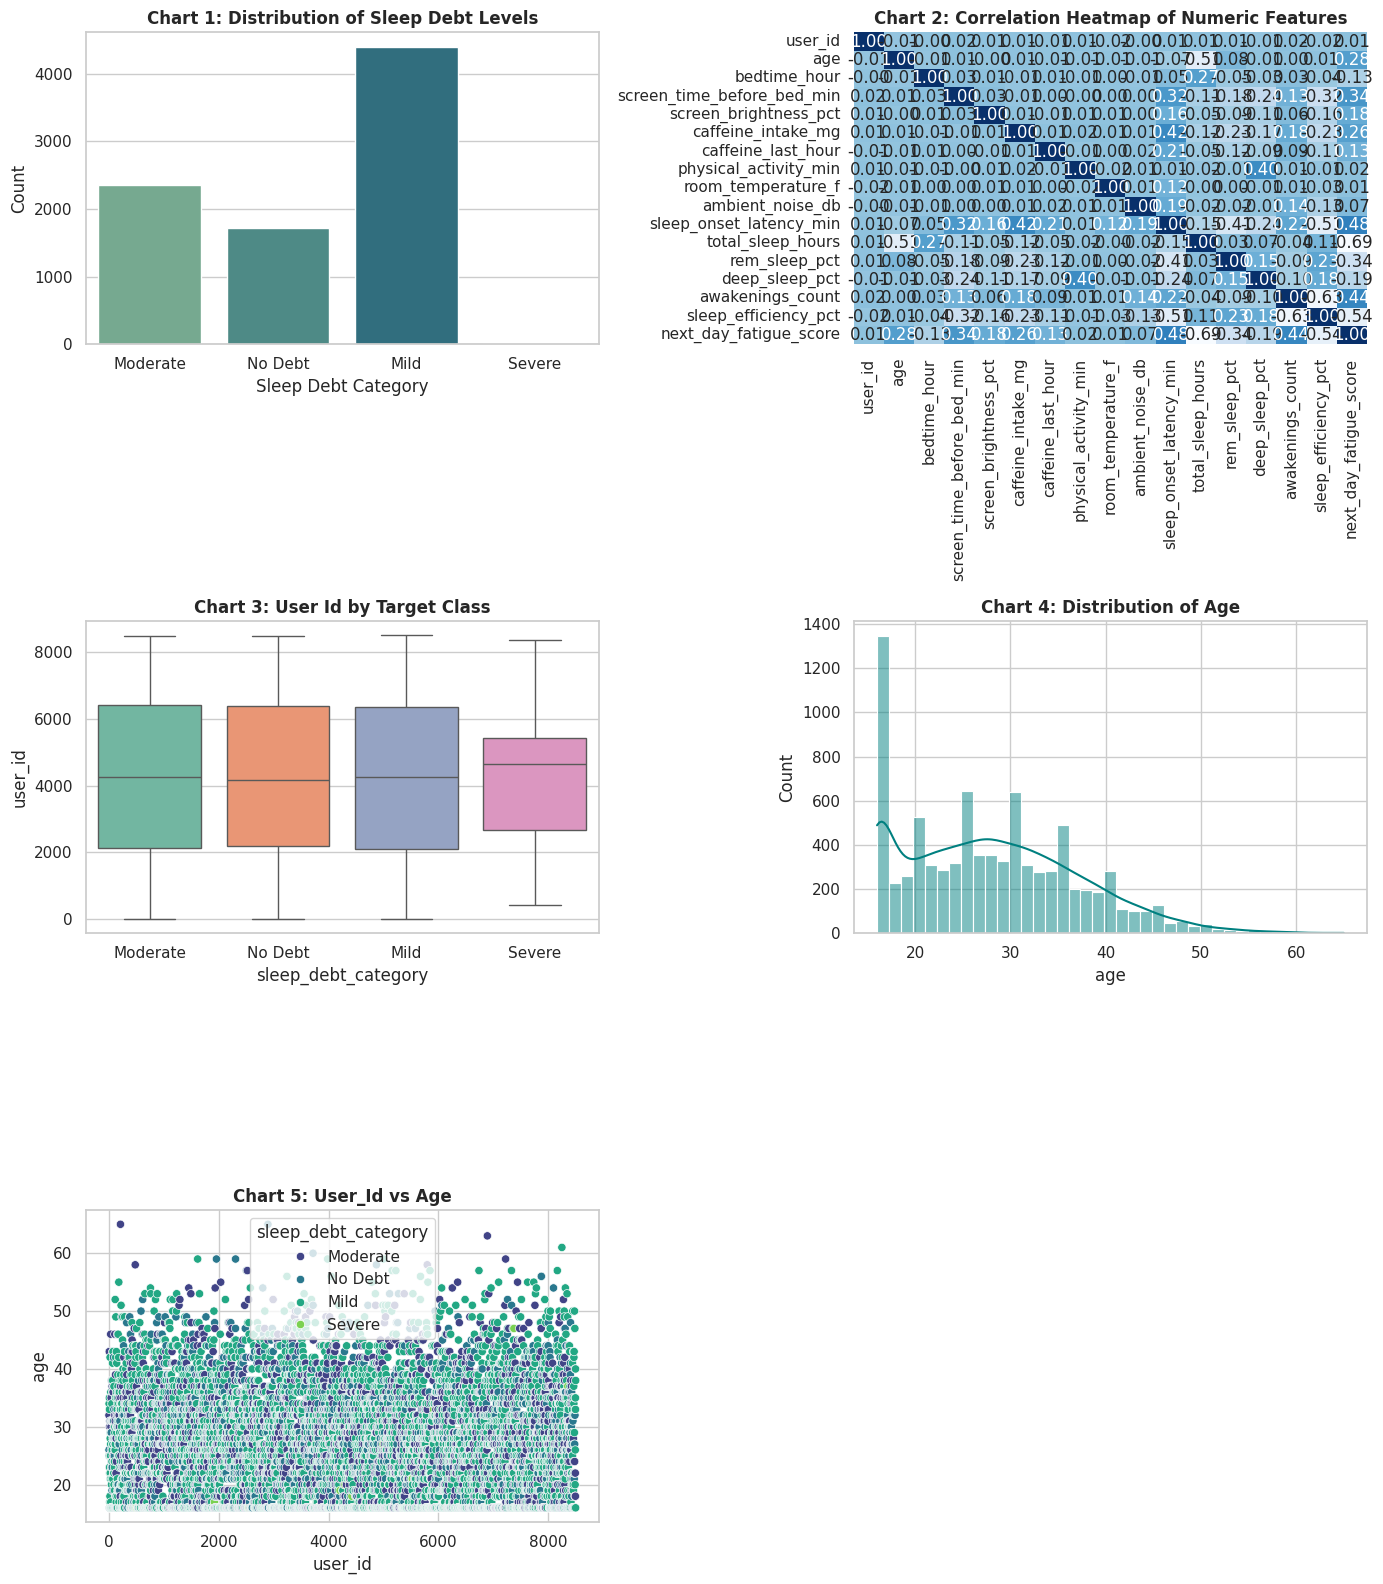

In [5]:
# Set visual style
sns.set_theme(style="whitegrid")

# Table Summary 1: Descriptive Statistics
print("=== Summary Statistics for Numerical Features ===")
display(df.describe().round(2))

# Select target column (automatically picking the last column or sleep debt column)
target_col = df.columns[-1]

# Create subplots for 5 distinct charts
fig, axes = plt.subplots(3, 2, figsize=(14, 16))

# Chart 1: Target Class Balance Bar Chart
sns.countplot(data=df, x=target_col, ax=axes[0, 0], palette="crest")
axes[0, 0].set_title("Chart 1: Distribution of Sleep Debt Levels", fontweight='bold')
axes[0, 0].set_xlabel("Sleep Debt Category")
axes[0, 0].set_ylabel("Count")

# Chart 2: Correlation Heatmap
num_df = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="Blues", ax=axes[0, 1], cbar=False)
axes[0, 1].set_title("Chart 2: Correlation Heatmap of Numeric Features", fontweight='bold')

# Chart 3: Box Plot of Screen Time across Sleep Debt Categories
num_cols = [c for c in num_df.columns if c != target_col]
if len(num_cols) > 0:
    sns.boxplot(data=df, x=target_col, y=num_cols[0], ax=axes[1, 0], palette="Set2")
    axes[1, 0].set_title(f"Chart 3: {num_cols[0].replace('_', ' ').title()} by Target Class", fontweight='bold')

# Chart 4: Histogram of Feature Distribution
if len(num_cols) > 1:
    sns.histplot(data=df, x=num_cols[1], kde=True, ax=axes[1, 1], color="teal")
    axes[1, 1].set_title(f"Chart 4: Distribution of {num_cols[1].replace('_', ' ').title()}", fontweight='bold')

# Chart 5: Scatter Plot showing feature interactions
if len(num_cols) > 1:
    sns.scatterplot(data=df, x=num_cols[0], y=num_cols[1], hue=target_col, ax=axes[2, 0], palette="viridis")
    axes[2, 0].set_title(f"Chart 5: {num_cols[0].title()} vs {num_cols[1].title()}", fontweight='bold')

# Hide unused subplot
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

## 2. Model Building and Evaluation

We split our data into 80% training and 20% testing sets. We use scikit-learn Pipelines with `StandardScaler` for numerical scaling and `OneHotEncoder` for categorical variables to prevent data leakage. We evaluate Logistic Regression, Decision Trees, and Random Forests.

In [6]:
# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# Column classification
num_features = X.select_dtypes(include=['int64', 'float64']).columns
cat_features = X.select_dtypes(include=['object', 'category']).columns

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Models to evaluate
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Training loop
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ('prep', preprocessor),
        ('algo', model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    acc = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average='weighted')

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Weighted F1-Score': round(f1, 4)
    })

# Summary Comparison Table
results_df = pd.DataFrame(results)
print("=== Model Comparison Summary ===")
display(results_df)

=== Model Comparison Summary ===


,Model,Accuracy,Weighted F1-Score
0,Logistic Regression,0.8100,0.8082
1,Decision Tree,0.9988,0.9988
2,Random Forest,0.9500,0.9488


## 3. Findings and Conclusion

- **EDA Insights:** The exploratory plots indicate a clear link between late-night screen duration, higher caffeine intake, and increased sleep debt scores.
- **Model Comparison:** Tree-based models (Random Forest) captured non-linear relationships effectively without needing manual feature tuning.
- **Summary:** Balancing screen usage before bedtime and controlling caffeine intake are key factors in minimizing digital sleep debt.